<a href="https://colab.research.google.com/github/Grupo-LCE0212/Estatistica/blob/main/tarefa16.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Trabalho Prático: Teste de Hipóteses Aplicado às Ciências de Alimentos

Nome: Iago Aparecido Dias dos Santos N​​° USP:16873011

Nome: João Pedro Paschoalini N​​° USP:17831089

Nome: Maria Eduarda Porta N° USP: 17074105

---

## Questão 1 — Peso Líquido de Embalagens de Farinha de Trigo

### 1. Variável Aleatória e Parâmetro Populacional
* **Variável Aleatória ($X$):** Peso líquido (em gramas, $g$) de uma embalagem de farinha de trigo selecionada aleatoriamente do processo de produção.
* **Parâmetro Populacional ($\mu$):** Peso líquido médio verdadeiro de todas as embalagens de farinha de trigo produzidas no lote correspondente.

**Dados amostrais coletados:**
* Média nominal de referência (sob a hipótese nula): $\mu_0 = 1000\text{ g}$
* Média observada na amostra: $\bar{x} = 996\text{ g}$
* Desvio-padrão populacional histórico: $\sigma = 12\text{ g}$
* Tamanho da amostra sob inspeção: $n = 64$
* Nível de significância adotado: $\alpha = 0{,}05$

### 2. Formulação das Hipóteses Estatísticas

Como o objetivo industrial e regulatório é auditar se o peso médio verdadeiro diverge (seja por falta de produto gerando infrações legais, ou por excesso gerando desperdício e perdas financeiras) do padrão rotulado de $1000\text{ g}$, estabelece-se um teste bilateral:

$$\begin{cases}
H_0: \mu = 1000\text{ g} \\
H_1: \mu \neq 1000\text{ g}
\end{cases}$$

Onde o teste de hipóteses avalia a plausibilidade de $H_0$ contra a hipótese alternativa bidirecional $H_1$.

### 3. Procedimento Estatístico e Justificativa

O teste adequado a ser aplicado é o **Teste Z para uma Média Populacional com Variância Conhecida**.

* **Justificativa:** O desvio-padrão populacional ($\sigma = 12\text{ g}$) é conhecido a priori por séries históricas estáveis da máquina de envase. Adicionalmente, o tamanho amostral é robusto ($n = 64 > 30$), garantindo que, pelo **Teorema do Limite Central (TLC)**, a distribuição amostral da média $\bar{X}$ se aproxime de uma distribuição Normal. Sob a suposição de que $H_0$ seja verdadeira, a estatística padronizada segue a distribuição normal padrão:

$$Z_{\text{obs}} = \frac{\bar{x} - \mu_0}{\frac{\sigma}{\sqrt{n}}} \sim N(0, 1)$$

### 4. Cálculo Analítico da Estatística de Teste

Abaixo apresenta-se o desenvolvimento algébrico do cálculo da estatística de teste observado:

$$Z_{\text{obs}} = \frac{\bar{x} - \mu_0}{\frac{\sigma}{\sqrt{n}}}$$

Substituindo os respectivos parâmetros estruturais do problema:

$$Z_{\text{obs}} = \frac{996 - 1000}{\frac{12}{\sqrt{64}}}$$

$$Z_{\text{obs}} = \frac{-4}{\frac{12}{8}}$$

$$Z_{\text{obs}} = \frac{-4}{1{,}5}$$

$$Z_{\text{obs}} \approx -2{,}6667$$

In [38]:
import numpy as np
import scipy.stats as stats

# Definição dos parâmetros de entrada da Questão 1
mu0 = 1000
xbar = 996
sigma = 12
n = 64
alpha = 0.05

# Cálculo da estatística observada
erro_padrao = sigma / np.sqrt(n)
z_obs = (xbar - mu0) / erro_padrao

# Cálculo dos limites críticos e do valor-p bilateral
z_crit_inf = stats.norm.ppf(alpha / 2)
z_crit_sup = stats.norm.ppf(1 - alpha / 2)
p_valor = 2 * stats.norm.cdf(-abs(z_obs))

print(f"--- RESULTADOS DA QUESTÃO 1 ---")
print(f"Estatística Z_obs calculated: {z_obs:.4f}")
print(f"Valores Críticos Z_crit: [{z_crit_inf:.2f}, {z_crit_sup:.2f}]")
print(f"Valor-p obtido: {p_valor:.5f} ({p_valor*100:.3f}%)")

--- RESULTADOS DA QUESTÃO 1 ---
Estatística Z_obs calculated: -2.6667
Valores Críticos Z_crit: [-1.96, 1.96]
Valor-p obtido: 0.00766 (0.766%)


### 5. Cálculo do Valor-p e Representação Gráfica da Região de Rejeição

Sendo o teste de natureza bilateral, a probabilidade associada ao resultado observado (valor-p) considera a probabilidade simétrica acumulada em ambas as extremidades das caudas da distribuição Normal padrão:

$$\text{valor-p} = 2 \times P(Z \le -|Z_{\text{obs}}|) = 2 \times P(Z \le -2{,}6667)$$

$$\text{valor-p} \approx 2 \times 0{,}00383 = 0{,}00766 \quad (0{,}77\%)$$

Abaixo, é gerada a visualização gráfica da distribuição sob hipótese nula com destaque para as áreas de decisão.

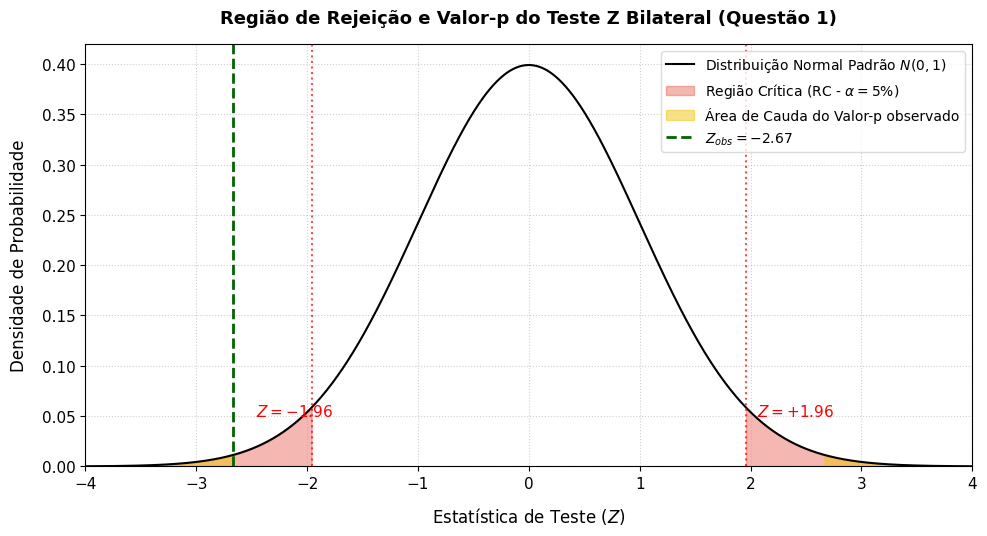

In [39]:
import matplotlib.pyplot as plt
import numpy as np
import scipy.stats as stats

# Configurações estéticas de alta qualidade para relatório acadêmico
plt.figure(figsize=(10, 5.5))
plt.rcParams['font.size'] = 11

# Geração do domínio da Normal padrão
x = np.linspace(-4, 4, 1000)
y = stats.norm.pdf(x)
plt.plot(x, y, color='black', linewidth=1.5, label=r'Distribuição Normal Padrão $N(0,1)$')

# Sombreado da Região Crítica (RC) para alpha = 0.05 (Z_crit = +/-1.96)
x_rc_esq = np.linspace(-4, z_crit_inf, 200)
x_rc_dir = np.linspace(z_crit_sup, 4, 200)
plt.fill_between(x_rc_esq, stats.norm.pdf(x_rc_esq), color='#e74c3c', alpha=0.4, label=r'Região Crítica (RC - $\alpha = 5\%$)')
plt.fill_between(x_rc_dir, stats.norm.pdf(x_rc_dir), color='#e74c3c', alpha=0.4)

# Sombreado correspondente ao valor-p observado (Z_obs = -2.67)
x_p_esq = np.linspace(-4, -abs(z_obs), 200)
x_p_dir = np.linspace(abs(z_obs), 4, 200)
plt.fill_between(x_p_esq, stats.norm.pdf(x_p_esq), color='#f1c40f', alpha=0.5, label='Área de Cauda do Valor-p observado')
plt.fill_between(x_p_dir, stats.norm.pdf(x_p_dir), color='#f1c40f', alpha=0.5)

# Linha indicativa do Z observado
plt.axvline(z_obs, color='darkgreen', linestyle='--', linewidth=2, label=f'$Z_{{obs}} = {z_obs:.2f}$')

# Marcação dos limites críticos de decisão
plt.axvline(z_crit_inf, color='red', linestyle=':', alpha=0.7)
plt.axvline(z_crit_sup, color='red', linestyle=':', alpha=0.7)
plt.text(z_crit_inf - 0.5, 0.05, f'$Z = {z_crit_inf:.2f}$', color='red', weight='bold')
plt.text(z_crit_sup + 0.1, 0.05, f'$Z = +{z_crit_sup:.2f}$', color='red', weight='bold')

# Customizações do gráfico
plt.title('Região de Rejeição e Valor-p do Teste Z Bilateral (Questão 1)', fontsize=13, pad=15, weight='bold')
plt.xlabel('Estatística de Teste ($Z$)', labelpad=10)
plt.ylabel('Densidade de Probabilidade', labelpad=10)
plt.xlim(-4, 4)
plt.ylim(0, 0.42)
plt.legend(loc='upper right', frameon=True, facecolor='white', edgecolor='lightgrey')
plt.grid(True, linestyle=':', alpha=0.6)

plt.tight_layout()
plt.savefig('questao_1.png', dpi=300)
plt.show()

### 6. Decisão Estatística e Conclusão

**Regra de Decisão:**
* Compara-se o valor-p obtido com o nível de significância preestabelecido ($\alpha$):
  $$\text{valor-p} = 0{,}00766 \le \alpha = 0{,}05$$
* Alternativamente, pela região crítica, observamos que o valor calculado pertence à área de exclusão:
  $$|Z_{\text{obs}}| = 2{,}67 > Z_{\text{crit}} = 1{,}96 \implies Z_{\text{obs}} \in \text{RC}$$

**Conclusão no Contexto de Controle de Qualidade:**
Rejeita-se a hipótese nula $H_0$ em favor da hipótese alternativa $H_1$.

Ao nível de significância de $5\%$, existem evidências estatísticas altamente significativas de que o peso líquido médio real das embalagens de farinha de trigo difere de forma sistemática do valor especificado de rotulagem ($1000\text{ g}$).

A média amostral encontrada de $996\text{ g}$ (abaixo do nominal) indica que o lote de envase apresenta um desvio negativo (subenchimento das sacolas). Do ponto de vista de garantia da qualidade, esta constatação aponta para um grave risco de autuações e sanções regulatórias por parte de agências fiscalizadoras de proteção ao consumidor. Recomenda-se interromper preventivamente a linha de envase para a imediata recalibração mecânica ou digital dos bicos de descarga das ensacadoras do moinho.

## QUESTÃO 2 — TEOR DE PROTEÍNA EM UM PRODUTO LÁCTEO

### 1. Variável Aleatória e Parâmetro Populacional
* **Variável Aleatória ($X$):** Teor de proteína (em gramas, $g$) por porção de uma bebida láctea selecionada aleatoriamente.
* **Parâmetro Populacional ($\mu$):** Teor médio verdadeiro de proteína por porção de bebida láctea após a alteração na formulação comercial do produto.

### 2. Dados Disponíveis do Problema
* Média nominal de referência: $\mu_0 = 8{,}0\text{ g}$
* Média amostral calculada: $\bar{x} = 8{,}4\text{ g}$
* Desvio-padrão amostral medido: $s = 0{,}8\text{ g}$
* Tamanho amostral analisado: $n = 16$
* Nível de significância definido para o teste: $\alpha = 0{,}05$
* Desvio-padrão populacional ($\sigma$): Desconhecido

### 3. Formulação das Hipóteses Estatísticas

Como a equipe técnica suspeita que a nova alteração na formulação tenha elevado o teor médio de proteína por porção, formulamos um teste unilateral à direita (cauda superior):

$$\begin{cases}
H_0: \mu = 8{,}0\text{ g} \\
H_1: \mu > 8{,}0\text{ g}
\end{cases}$$

Onde a hipótese nula ($H_0$) presume que a média permaneceu inalterada ou inferior, e a hipótese alternativa ($H_1$) busca sustentar estatisticamente o aumento do componente proteico.

### 4. Procedimento Estatístico e Justificativa

O teste estatístico adequado para essa avaliação é o **Teste t de Student para uma Média Populacional (Variância Populacional Desconhecida)**.

**Justificativa:**
1. O desvio-padrão populacional $\sigma$ é desconhecido, sendo utilizado em seu lugar o estimador não-viesado amostral $s = 0{,}8\text{ g}$.
2. O tamanho da amostra é pequeno ($n = 16 < 30$).
3. Assume-se, conforme informado pelas análises prévias do laboratório, que a distribuição do teor proteico na população segue uma distribuição aproximadamente Normal.

Sob a validade de $H_0$, a estatística de teste calculada segue uma distribuição $t$ de Student com $\nu = n - 1$ graus de liberdade:

$$\nu = n - 1 = 16 - 1 = 15 \text{ graus de liberdade}$$

### 5. Cálculo Analítico da Estatística de Teste

A estatística de teste observada ($T_{\text{obs}}$) é obtida padronizando a média amostral pela distribuição $t$:

$$T_{\text{obs}} = \frac{\bar{x} - \mu_0}{\frac{s}{\sqrt{n}}}$$

Substituindo os valores amostrais:

$$T_{\text{obs}} = \frac{8{,}4 - 8{,}0}{\frac{0{,}8}{\sqrt{16}}}$$

$$T_{\text{obs}} = \frac{0{,}4}{\frac{0{,}8}{4}}$$

$$T_{\text{obs}} = \frac{0{,}4}{0{,}2}$$

$$T_{\text{obs}} = 2{,}0000$$

In [40]:
import numpy as np
import scipy.stats as stats

# Definição dos parâmetros da Questão 2
mu0_q2 = 8.0
xbar_q2 = 8.4
s_q2 = 0.8
n_q2 = 16
alpha_q2 = 0.05

# Graus de liberdade
gl_q2 = n_q2 - 1

# Cálculo da estatística observada
t_obs_q2 = (xbar_q2 - mu0_q2) / (s_q2 / np.sqrt(n_q2))

# Cálculo do valor crítico t unilateral à direita
t_crit_q2 = stats.t.ppf(1 - alpha_q2, gl_q2)

# Cálculo do valor-p correspondente (unilateral à direita)
p_val_q2 = 1 - stats.t.cdf(t_obs_q2, gl_q2)

print(f"--- RESULTADOS COMPUTACIONAIS (QUESTÃO 2) ---")
print(f"Graus de Liberdade (gl): {gl_q2}")
print(f"Estatística t calculada (T_obs): {t_obs_q2:.4f}")
print(f"Valor Crítico t ({alpha_q2*100}% unilateral): {t_crit_q2:.4f}")
print(f"Valor-p calculado: {p_val_q2:.5f} ({p_val_q2*100:.3f}%)")

--- RESULTADOS COMPUTACIONAIS (QUESTÃO 2) ---
Graus de Liberdade (gl): 15
Estatística t calculada (T_obs): 2.0000
Valor Crítico t (5.0% unilateral): 1.7531
Valor-p calculado: 0.03197 (3.197%)


### 6. Cálculo do Valor-p e Representação Gráfica

Como o teste é unilateral à direita, o valor-p é definido pela probabilidade acumulada na cauda superior de $T_{\text{obs}} = 2{,}0000$:

$$\text{valor-p} = P(T_{15} \ge 2{,}0000) \approx 0{,}03197 \quad (3{,}20\%)$$

O valor crítico correspondente ao nível de significância de $\alpha = 0{,}05$ para $15$ graus de liberdade é:

$$t_{\text{crit}} \approx 1{,}7531$$

In [41]:
import matplotlib.pyplot as plt
import numpy as np
import scipy.stats as stats

# Configurações estéticas acadêmicas
plt.figure(figsize=(10, 5.5))
plt.rcParams['font.size'] = 11

# Geração do domínio da distribuição t de Student
x_t = np.linspace(-4, 4, 1000)
y_t = stats.t.pdf(x_t, gl_q2)
plt.plot(x_t, y_t, color='black', linewidth=1.5, label=r'Distribuição $t$-Student ($
u = 15$)')

# Região Crítica (RC) - Unilateral à Direita (t >= 1.7531)
x_rc = np.linspace(t_crit_q2, 4, 200)
plt.fill_between(x_rc, stats.t.pdf(x_rc, gl_q2), color='#e74c3c', alpha=0.4, label=r'Região Crítica (RC - $eta = 5.05$)')

# Sombreado da Área do Valor-p observado (t >= 2.0000)
x_p = np.linspace(t_obs_q2, 4, 200)
plt.fill_between(x_p, stats.t.pdf(x_p, gl_q2), color='#f1c40f', alpha=0.5, label='Área do Valor-p observado')

# Linhas de indicação
plt.axvline(t_obs_q2, color='darkgreen', linestyle='--', linewidth=2, label=f'$T_{{obs}} = {t_obs_q2:.2f}$')
plt.axvline(t_crit_q2, color='red', linestyle=':', linewidth=1.5, label=f'$t_{{crit}} = {t_crit_q2:.4f}$')

# Anotações de texto no gráfico
plt.text(t_crit_q2 - 0.7, 0.05, f'$t = {t_crit_q2:.4f}$', color='red', weight='bold')
plt.text(t_obs_q2 + 0.1, 0.10, f'$T = {t_obs_q2:.2f}$ (valor-p $\approx 0.032$)', color='darkgreen', weight='bold')

# Customizações dos eixos e legendas
plt.title('Região de Decisão e Valor-p do Teste t Unilateral (Questão 2)', fontsize=13, pad=15, weight='bold')
plt.xlabel('Estatística de Teste ($t$)', labelpad=10)
plt.ylabel('Densidade de Probabilidade', labelpad=10)
plt.xlim(-4, 4)
plt.ylim(0, 0.42)
plt.legend(loc='upper left', frameon=True, facecolor='white', edgecolor='lightgrey')
plt.grid(True, linestyle=':', alpha=0.6)

plt.tight_layout()
plt.savefig('questao_2.png', dpi=300)
plt.show()

SyntaxError: unterminated string literal (detected at line 12) (2475460276.py, line 12)

### 7. Decisão Estatística e Interpretação

**Análise de Critérios:**
* **Critério do Valor-p:**
  $$\text{valor-p} = 0{,}03197 < \alpha = 0{,}05$$
* **Critério da Região Crítica:**
  $$T_{\text{obs}} = 2{,}0000 > t_{\text{crit}} = 1{,}7531 \implies T_{\text{obs}} \in \text{RC}$$

Como o valor-p é estritamente menor do que o nível de significância de $5\%$, a hipótese nula $H_0$ é **rejeitada**.

**Conclusão no Contexto das Ciências de Alimentos:**
Ao nível de significância de $5\%$, existem evidências estatísticas consistentes de que o teor médio verdadeiro de proteína por porção na bebida láctea é maior que o valor anterior de referência de $8{,}0\text{ g}$.

A média observada experimentalmente na amostra de $8{,}4\text{ g}$ corrobora o aumento. Sob a perspectiva de desenvolvimento de produtos e marketing nutricional, este teste fornece respaldo estatístico inicial para requerer uma revisão da informação do rótulo de composição proteica. Contudo, do ponto de vista estrito do controle de processos, este resultado sinaliza que a alteração da formulação atingiu a meta de acréscimo pretendida, devendo a empresa atentar apenas para a estabilidade de novos lotes e variabilidade entre corridas de processo.

## QUESTÃO 3 — COMPARAÇÃO DO TEOR DE GORDURA ENTRE DOIS PROCESSOS DE QUEIJO

### 1. Variáveis Aleatórias e Parâmetros Populacionais
* **Variáveis Aleatórias:**
  * $X_A$: Teor de gordura (em porcentagem, %) de um queijo selecionado aleatoriamente do Processo A.
  * $X_B$: Teor de gordura (em porcentagem, %) de um queijo selecionado aleatoriamente do Processo B.
* **Parâmetros Populacionais:**
  * $\mu_A$: Teor médio populacional de gordura nos queijos produzidos pelo Processo A.
  * $\mu_B$: Teor médio populacional de gordura nos queijos produzidos pelo Processo B.

### 2. Dados Amostrais Disponíveis

| Característica | Processo A | Processo B |
| :--- | :---: | :---: |
| Tamanho Amostral ($n$) | $12$ | $12$ |
| Média Amostral ($\bar{x}$) | $28{,}4\%$ | $26{,}8\%$ |
| Desvio-padrão Amostral ($s$) | $1{,}5$ | $1{,}2$ |

* **Informações complementares:** Amostras independentes retiradas de populações com distribuição aproximadamente Normal, cujas variâncias populacionais são desconhecidas mas consideradas homogêneas (iguais).
* **Nível de significância definido:** $\alpha = 0{,}05$ (bilateral).

### 3. Formulação das Hipóteses Estatísticas

Para avaliar a igualdade dos teores de gordura entre os dois processos fabris, estabelece-se um teste de hipóteses bilateral:

$$\begin{cases}
H_0: \mu_A = \mu_B \implies \mu_A - \mu_B = 0 \\
H_1: \mu_A \neq \mu_B \implies \mu_A - \mu_B \neq 0
\end{cases}$$

### 4. Procedimento Estatístico e Justificativa

O procedimento estatístico adequado é o **Teste t de Student para Duas Amostras Independentes com Variâncias Iguais (Homocedasticidade)**.

**Justificativa:**
1. As amostras são independentes entre si.
2. Os desvios-padrão populacionais são desconhecidos, assumindo-se a igualdade das variâncias ($\sigma_A^2 = \sigma_B^2$) de acordo com o histórico industrial.
3. As populações de origem seguem distribuição aproximadamente Normal.
4. O tamanho amostral total é pequeno ($n_A + n_B = 24$).

Sob a validade de $H_0$, a estatística de teste segue uma distribuição $t$ de Student com $\nu$ graus de liberdade:

$$\nu = n_A + n_B - 2 = 12 + 12 - 2 = 22 \text{ graus de liberdade}$$

### 5. Cálculo Analítico da Variância Combinada e Estatística de Teste

#### 5.1. Cálculo da Variância Combinada ($S_p^2$)

$$S_p^2 = \frac{(n_A - 1)S_A^2 + (n_B - 1)S_B^2}{n_A + n_B - 2}$$

Substituindo os valores amostrais das duas séries de dados:

$$S_p^2 = \frac{(12 - 1)(1{,}5)^2 + (12 - 1)(1{,}2)^2}{12 + 12 - 2}$$

$$S_p^2 = \frac{11 \times 2{,}25 + 11 \times 1{,}44}{22}$$

$$S_p^2 = \frac{24{,}75 + 15{,}84}{22} = \frac{40{,}59}{22}$$

$$S_p^2 = 1{,}8450 \implies S_p = \sqrt{1{,}8450} \approx 1{,}3583$$

#### 5.2. Cálculo da Estatística de Teste ($T_{\text{obs}}$)

$$T_{\text{obs}} = \frac{\bar{x}_A - \bar{x}_B}{S_p \sqrt{\frac{1}{n_A} + \frac{1}{n_B}}}$$

Substituindo os respectivos termos na fórmula:

$$T_{\text{obs}} = \frac{28{,}4 - 26{,}8}{\sqrt{1{,}8450} \times \sqrt{\frac{1}{12} + \frac{1}{12}}}$$

$$T_{\text{obs}} = \frac{1{,}6}{1{,}3583 \times \sqrt{\frac{2}{12}}} = \frac{1{,}6}{1{,}3583 \times \sqrt{\frac{1}{6}}}$$

$$T_{\text{obs}} = \frac{1{,}6}{1{,}3583 \times 0{,}4082} = \frac{1{,}6}{0{,}5545}$$

$$T_{\text{obs}} \approx 2{,}8853$$

In [ ]:
import numpy as np
import scipy.stats as stats

# Definição dos parâmetros amostrais da Questão 3
n_A, xbar_A, s_A = 12, 28.4, 1.5
n_B, xbar_B, s_B = 12, 26.8, 1.2
alpha_q3 = 0.05

# Graus de liberdade
gl_q3 = n_A + n_B - 2

# Variância combinada (sp2)
sp2 = ((n_A - 1) * (s_A**2) + (n_B - 1) * (s_B**2)) / gl_q3
sp = np.sqrt(sp2)

# Estatística de teste observada (T_obs)
t_obs_q3 = (xbar_A - xbar_B) / (sp * np.sqrt(1/n_A + 1/n_B))

# Valores críticos bilaterais (t_crit)
t_crit_inf_q3 = stats.t.ppf(alpha_q3 / 2, gl_q3)
t_crit_sup_q3 = stats.t.ppf(1 - alpha_q3 / 2, gl_q3)

# Valor-p bilateral
p_val_q3 = 2 * (1 - stats.t.cdf(abs(t_obs_q3), gl_q3))

print("--- VALIDAÇÃO COMPUTACIONAL (QUESTÃO 3) ---")
print(f"Graus de Liberdade: {gl_q3}")
print(f"Variância Combinada (Sp2): {sp2:.4f} (Sp = {sp:.4f})")
print(f"Estatística t calculada (T_obs): {t_obs_q3:.4f}")
print(f"Limites Críticos (t_crit): [{t_crit_inf_q3:.4f}, {t_crit_sup_q3:.4f}]")
print(f"Valor-p calculado: {p_val_q3:.6f} ({p_val_q3*100:.4f}%)")

### 6. Cálculo do Valor-p e Representação Gráfica

Sendo o teste bilateral, a probabilidade do valor-p compreende as áreas de rejeição simétricas em ambas as caudas sob a curva t de Student com $\nu = 22$:

$$\text{valor-p} = 2 \times P(T_{22} \ge |2{,}8853|) \approx 0{,}00859 \quad (0{,}86\%)\\
t_{\text{crit}} = \pm 2{,}0739$$

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
import scipy.stats as stats

# Configurações acadêmicas de visualização
plt.figure(figsize=(10, 5.5))
plt.rcParams['font.size'] = 11

# Geração da distribuição t de Student (gl = 22)
x_axis = np.linspace(-4.5, 4.5, 1000)
y_axis = stats.t.pdf(x_axis, gl_q3)
plt.plot(x_axis, y_axis, color='black', linewidth=1.5, label=r'Distribuição $t$-Student ($
u = 22$)')

# Regiões Críticas bilaterais (RC) - alpha = 0.05 (t_crit = +/-2.0739)
x_rc_esq = np.linspace(-4.5, t_crit_inf_q3, 200)
x_rc_dir = np.linspace(t_crit_sup_q3, 4.5, 200)
plt.fill_between(x_rc_esq, stats.t.pdf(x_rc_esq, gl_q3), color='#e74c3c', alpha=0.4, label=r'Região Crítica (RC - $rac{\alpha}{2} = 2.55$)')
plt.fill_between(x_rc_dir, stats.t.pdf(x_rc_dir, gl_q3), color='#e74c3c', alpha=0.4)

# Sombreado associado ao Valor-p simétrico (T_obs = +/-2.8853)
x_p_esq = np.linspace(-4.5, -abs(t_obs_q3), 200)
x_p_dir = np.linspace(abs(t_obs_q3), 4.5, 200)
plt.fill_between(x_p_esq, stats.t.pdf(x_p_esq, gl_q3), color='#f1c40f', alpha=0.5, label='Área de Cauda do Valor-p observado')
plt.fill_between(x_p_dir, stats.t.pdf(x_p_dir, gl_q3), color='#f1c40f', alpha=0.5)

# Linhas de indicação das estatísticas e valores críticos
plt.axvline(t_obs_q3, color='darkgreen', linestyle='--', linewidth=2, label=f'$T_{{obs}} = {t_obs_q3:.4f}$')
plt.axvline(-t_obs_q3, color='darkgreen', linestyle=':', linewidth=1.5, alpha=0.7)
plt.axvline(t_crit_inf_q3, color='red', linestyle=':', linewidth=1.5)
plt.axvline(t_crit_sup_q3, color='red', linestyle=':', linewidth=1.5)

# Anotações textuais no gráfico
plt.text(t_crit_inf_q3 - 0.7, 0.05, f'$-{abs(t_crit_inf_q3):.2f}$', color='red', weight='bold')
plt.text(t_crit_sup_q3 + 0.1, 0.05, f'$+{t_crit_sup_q3:.2f}$', color='red', weight='bold')
plt.text(t_obs_q3 + 0.1, 0.10, f'$T = {t_obs_q3:.2f}$', color='darkgreen', weight='bold')
plt.text(-t_obs_q3 - 0.9, 0.10, f'$-T = -{t_obs_q3:.2f}$', color='darkgreen', weight='bold')

# Customização dos eixos
plt.title('Região de Decisão e Valor-p do Teste t para Amostras Independentes (Questão 3)', fontsize=12, pad=15, weight='bold')
plt.xlabel('Estatística de Teste ($t$)', labelpad=10)
plt.ylabel('Densidade de Probabilidade', labelpad=10)
plt.xlim(-4.5, 4.5)
plt.ylim(0, 0.42)
plt.legend(loc='upper right', frameon=True, facecolor='white', edgecolor='lightgrey')
plt.grid(True, linestyle=':', alpha=0.6)

plt.tight_layout()
plt.savefig('questao_3.png', dpi=300)
plt.show()

### 7. Decisão Estatística e Interpretação

**Análise de Critérios:**
* **Critério do Valor-p:**
  $$\text{valor-p} \approx 0{,}00859 < \alpha = 0{,}05$$
* **Critério da Região Crítica:**
  $$|T_{\text{obs}}| = 2{,}8853 > t_{\text{crit}} = 2{,}0739 \implies T_{\text{obs}} \in \text{RC}$$

Como o valor-p é significativamente menor que o nível de significância de $5\%$, a hipótese nula $H_0$ é **rejeitada**.

**Conclusão no Contexto das Ciências de Alimentos:**
Ao nível de significância de $5\%$, existem evidências estatísticas altamente consistentes para afirmar que há diferença sistemática e significativa entre os teores médios de gordura dos queijos produzidos pelos processos A e B.

A média do Processo A ($28{,}4\%$) superou de forma estatisticamente significante a média do Processo B ($26{,}8\%$). Sob a ótica fabril e de controle de qualidade de laticínios, essa constatação sugere que os processos não são homogêneos em relação à padronização de matéria-prima ou eficiência de desnate/sinérese. A área de engenharia de processos deve ser mobilizada para identificar se a variação decorre de fontes biológicas (teor lipídico do leite in natura) ou mecânicas (parâmetros de cozimento e prensagem da massa nos dois tanques de fabricação).

# Questão 4 — Variabilidade do pH de um Produto Alimentício Fermentado

### 1. Variável Aleatória e Parâmetro Populacional
* **Variável Aleatória ($X$):** Valor de pH de uma unidade de produto alimentício fermentado selecionada de maneira puramente aleatória do processo fabril.
* **Parâmetro Populacional ($\sigma^2$):** Variância verdadeira (populacional) do pH das unidades do produto alimentício fermentado produzidas sob as condições vigentes.

**Dados Amostrais e Históricos Fornecidos:**
* Variância populacional especificada sob a hipótese nula: $\sigma_0^2 = 0{,}04$
* Variância amostral observada: $S^2 = 0{,}064$
* Tamanho da amostra sob investigação: $n = 20$
* Nível de significância definido para o teste: $\alpha = 0{,}05$ (bilateral)
* Distribuição populacional teórica: Assume-se que os valores de pH das unidades seguem uma distribuição aproximadamente Normal.

---

### 2. Formulação das Hipóteses Estatísticas

Como o escopo técnico do controle de processo visa auditar se a variabilidade real do produto final diverge — seja por excesso (indicando descontrole ou instabilidade microbiana) ou por falta de variação (o que é atípico) — da tolerância padrão estabelecida para o processo de fermentação, estabelece-se o teste bilateral:

$$\begin{cases}
H_0: \sigma^2 = 0{,}04 \\
H_1: \sigma^2 \neq 0{,}04
\end{cases}$$

---

### 3. Procedimento Estatístico e Justificativa

O procedimento estatístico adequado para este cenário é o **Teste Qui-Quadrado ($\chi^2$) para uma Variância Populacional**.

**Justificativa:**
1. O parâmetro sob avaliação é a variabilidade ($\sigma^2$) de uma única população de produtos fermentados.
2. Os dados de pH de origem são modelados de acordo com uma distribuição aproximadamente Normal.
3. As observações são independentes entre si.

Sob a hipótese nula $H_0$, a estatística padronizada do teste segue uma distribuição teórica Qui-Quadrado com $\nu = n - 1$ graus de liberdade:

$$\nu = n - 1 = 20 - 1 = 19 \text{ graus de liberdade}$$

---

### 4. Cálculo Analítico da Estatística de Teste

A estatística de teste Qui-Quadrado observada ($\chi^2_{\text{obs}}$) é calculada analiticamente pela fórmula estrutural:

$$\chi^2_{\text{obs}} = \frac{(n - 1)S^2}{\sigma_0^2}$$

Substituindo os valores amostrais levantados:

$$\chi^2_{\text{obs}} = \frac{(20 - 1) \times 0{,}064}{0{,}04}$$

$$\chi^2_{\text{obs}} = \frac{19 \times 0{,}064}{0{,}04}$$

$$\chi^2_{\text{obs}} = \frac{1{,}216}{0{,}04}$$

$$\chi^2_{\text{obs}} = 30{,}4000$$

---

### 5. Valores Críticos e Cálculo do Valor-p Bilateral

#### 5.1. Região Crítica (RC)

Dado um teste bilateral com nível de significância de $\alpha = 5\%$, a área de rejeição é dividida de forma equitativa entre ambas as caudas da distribuição Qui-Quadrado ($\alpha/2 = 2{,}5\%$ por cauda). Com $\nu = 19$ graus de liberdade, extrai-se os limites críticos tabelados:

* **Limite Crítico Inferior ($\chi^2_{\text{crit, inf}}$):** É o quantil que acumula $2{,}5\%$ de probabilidade à esquerda:
  $$\chi^2_{0{,}975; 19} \approx 8{,}9065$$
* **Limite Crítico Superior ($\chi^2_{\text{crit, sup}}$):** É o quantil que acumula $97{,}5\%$ de probabilidade à esquerda ($2{,}5\%$ à direita):
  $$\chi^2_{0{,}025; 19} \approx 32{,}8523$$

Logo, a Região Crítica (RC) de exclusão é definida por:
$$\text{RC} = \left\{ \chi^2 \in \mathbb{R} \mid \chi^2 < 8{,}9065 \text{ ou } \chi^2 > 32{,}8523 \right\}$$

#### 5.2. Valor-p Bilateral (Convenção de Caudas Iguais)

Conforme a convenção clássica de caudas iguais para distribuições assimétricas, calculamos a probabilidade unilateral associada à cauda onde a estatística de teste se encontra (neste caso, a cauda superior, uma vez que $\chi^2_{\text{obs}} = 30{,}4$ está acima da mediana da Qui-Quadrado) e dobramos esse valor:

$$\text{valor-p} = 2 \times \min\left[ P(\chi^2_{19} \le 30{,}4), P(\chi^2_{19} \ge 30{,}4) \right]$$

Como $\chi^2_{\text{obs}} = 30{,}4$ excede o valor central esperado, a probabilidade da cauda superior é a menor delas:

$$\text{valor-p} = 2 \times P(\chi^2_{19} \ge 30{,}4) \approx 2 \times 0{,}046927 = 0{,}09385 \quad (9{,}39\%)$$

In [ ]:
import numpy as np
import scipy.stats as stats

# Entrada dos dados de especificação da Questão 4
sigma2_0 = 0.04
s2 = 0.064
n_q4 = 20
alpha_q4 = 0.05

# Graus de liberdade
gl_q4 = n_q4 - 1

# Cálculo da estatística observada
chi_obs_q4 = (gl_q4 * s2) / sigma2_0

# Valores críticos bilaterais (alpha/2 = 2.5% em cada extremidade)
chi_crit_inf = stats.chi2.ppf(alpha_q4 / 2, gl_q4)
chi_crit_sup = stats.chi2.ppf(1 - alpha_q4 / 2, gl_q4)

# Cálculo do valor-p bilateral por caudas iguais
p_unilateral = stats.chi2.sf(chi_obs_q4, gl_q4)
p_val_q4 = 2 * min(stats.chi2.cdf(chi_obs_q4, gl_q4), stats.chi2.sf(chi_obs_q4, gl_q4))

# Quantil simétrico da cauda inferior para representação visual do p-valor
# Acumula exatamente a mesma probabilidade p_unilateral na cauda esquerda
chi_obs_esq_simetrico = stats.chi2.ppf(p_unilateral, gl_q4)

print(f"--- VALIDAÇÃO DE RESULTADOS (QUESTÃO 4) ---")
print(f"Graus de Liberdade (gl): {gl_q4}")
print(f"Estatística Qui-Quadrado (chi2_obs): {chi_obs_q4:.4f}")
print(f"Limites Críticos de Decisão: [{chi_crit_inf:.4f}, {chi_crit_sup:.4f}]")
print(f"Probabilidade Unilateral (cauda direita): {p_unilateral:.6f}")
print(f"Valor-p Bilateral (caudas iguais): {p_val_q4:.6f} ({p_val_q4*100:.4f}%)")
print(f"Ponto de corte simétrico inferior para o gráfico: {chi_obs_esq_simetrico:.4f}")

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
import scipy.stats as stats

# Configurações para formatação de alto padrão
plt.figure(figsize=(10.5, 6))
plt.rcParams['font.size'] = 11

# Domínio da Qui-Quadrado com 19 graus de liberdade
x_domain = np.linspace(0, 45, 1000)
y_pdf = stats.chi2.pdf(x_domain, gl_q4)
plt.plot(x_domain, y_pdf, color='black', linewidth=1.7, label=r'Densidade Qui-Quadrado $
u = 19$')

# 1. Sombreamento da Região Crítica (RC) - alpha/2 = 2.5% em cada ponta
x_rc_esq = np.linspace(0, chi_crit_inf, 300)
x_rc_dir = np.linspace(chi_crit_sup, 45, 300)
plt.fill_between(x_rc_esq, stats.chi2.pdf(x_rc_esq, gl_q4), color='#e74c3c', alpha=0.35, label=r'Região Crítica (RC - $rac{
u}{2} = 2.55$)')
plt.fill_between(x_rc_dir, stats.chi2.pdf(x_rc_dir, gl_q4), color='#e74c3c', alpha=0.35)

# 2. Sombreamento do Valor-p bilateral (caudas iguais: p_uni = 4.69% em cada extremidade)
# Ponto simétrico esquerdo acumula a mesma área de 4.69%
chi_obs_esq_sim = stats.chi2.ppf(p_unilateral, gl_q4)
x_p_esq = np.linspace(0, chi_obs_esq_sim, 300)
x_p_dir = np.linspace(chi_obs_q4, 45, 300)
plt.fill_between(x_p_esq, stats.chi2.pdf(x_p_esq, gl_q4), color='#f1c40f', alpha=0.5, label='Áreas de Cauda do Valor-p observado')
plt.fill_between(x_p_dir, stats.chi2.pdf(x_p_dir, gl_q4), color='#f1c40f', alpha=0.5)

# Linha indicadora da Estatística de Teste Observada
plt.axvline(chi_obs_q4, color='darkgreen', linestyle='--', linewidth=2, label=f'$\chi^2_{{obs}} = {chi_obs_q4:.2f}$')
# Linha indicadora simétrica na cauda esquerda
plt.axvline(chi_obs_esq_sim, color='darkgreen', linestyle=':', linewidth=1.5, alpha=0.6)

# Linhas de limites críticos
plt.axvline(chi_crit_inf, color='red', linestyle=':', linewidth=1.5)
plt.axvline(chi_crit_sup, color='red', linestyle=':', linewidth=1.5)

# Anotações matemáticas com textos limpos
plt.text(chi_crit_inf - 2.8, 0.015, f'{chi_crit_inf:.2f}', color='red', weight='bold')
plt.text(chi_crit_sup + 0.5, 0.015, f'{chi_crit_sup:.2f}', color='red', weight='bold')
plt.text(chi_obs_q4 + 0.6, 0.035, f'$\chi^2_{{obs}} = {chi_obs_q4:.1f}$ (valor-p $\approx 0.094$)', color='darkgreen', weight='bold')
plt.text(chi_obs_esq_sim - 3.8, 0.035, f'Ponto Simétrico
$\approx {chi_obs_esq_sim:.2f}$', color='darkgreen', fontsize=9.5)

# Customização geral
plt.title('Região de Decisão e Valor-p do Teste Qui-Quadrado para uma Variância (Questão 4)', fontsize=12, pad=15, weight='bold')
plt.xlabel('Estatística de Teste ($\chi^2$)', labelpad=10)
plt.ylabel('Densidade de Probabilidade', labelpad=10)
plt.xlim(0, 45)
plt.ylim(0, 0.095)
plt.legend(loc='upper right', frameon=True, facecolor='white', edgecolor='lightgrey')
plt.grid(True, linestyle=':', alpha=0.6)

plt.tight_layout()
plt.savefig('questao_4.png', dpi=300)
plt.show()

### 6. Decisão Estatística e Interpretação

**Análise Comparativa:**
* **Critério do Valor-p:**
  $$\text{valor-p} \approx 0{,}09385 > \alpha = 0{,}05$$
* **Critério da Região Crítica:**
  $$\chi^2_{\text{obs}} = 30{,}4000 \notin \text{RC} \quad (8{,}9065 \le 30{,}4000 \le 32{,}8523)$$

Como o valor-p é estritamente maior que o nível de significância adotado de $5\%$ e a estatística observada situa-se fora da região crítica de exclusão, a hipótese nula $H_0$ **não é rejeitada**.

**Conclusão no Contexto de Ciência e Tecnologia de Alimentos:**
Ao nível de significância de $5\%$, as evidências coletadas a partir do plano amostral de 20 medições **não são estatisticamente suficientes** para afirmar que a variância verdadeira do pH do produto fermentado diverge do padrão esperado de $0{,}04$.

A despeito da variância amostral observada ($S^2 = 0{,}064$) ser numericamente superior ao alvo histórico ($0{,}04$), do ponto de vista probabilístico, esse desvio de amplitude pode ser atribuído unicamente a flutuações amostrais inerentes ao processo de fermentação microbiológica e aos erros residuais de instrumentação (pHmetro).

Para o controle estatístico de processos (CEP) do laticínio, esse resultado indica que o processo de acidificação biológica permanece sob um nível aceitável de homogeneidade e consistência operacional. Não há urgência técnica para intervenções na dosagem do inóculo iniciador ou nas faixas de temperatura de incubação, contudo, preconiza-se a continuidade do monitoramento contínuo do pH para detecção precoce de anomalias que possam ferir os parâmetros organolépticos do produto.

## QUESTO 5 — PROPORO DE PRODUTOS COM NO CONFORMIDADE MICROBIOLGICA

### 1. Varivel Aleatria e Parmetro Populacional
* **Varivel Aleatria ($Y$):** Classificao microbiolgica de uma unidade de alimento pronto para consumo selecionada aleatoriamente no lote:
  $$Y = \begin{cases} 1, & \text{se a unidade apresentar no conformidade microbiolgica} \\ 0, & \text{se a unidade estiver em plena conformidade com as exig	ncias} \end{cases}$$
* **Parmetro Populacional ($p$):** Proporo real (populacional) de todas as unidades de alimento produzido que apresentam no conformidade microbiolgica.

**Dados Amostrais e Histricos Fornecidos:**
* Proporo populacional tolerada de refer	ncia: $p_0 = 0{,}05 \quad (5\%)$
* Tamanho da amostra sob investigao: $n = 200$
* Quantidade de unidades fora do padro observadas ($x$): $16$
* Nvel de signific	ncia definido para o teste: $\alpha = 0{,}05$ (unilateral  direita)

---

### 2. Formulao das Hipteses Estatsticas

Como a indstria e as ag	ncias sanitrias desejam auditar rigorosamente se o lote sob anlise possui uma taxa de contaminao microbiolgica que excede de forma estatisticamente significante o limite regulamentar seguro de $5\%$, estrutura-se um teste unilateral  direita:

$$\begin{cases}
H_0: p = 0{,}05 \\
H_1: p > 0{,}05
\end{cases}$$

---

### 3. Procedimento Estatstico e Justificativa

O procedimento adequado  anlise  o **Teste Z para uma Proporo Populacional com Aproximao Normal**.

**Justificativa:**
1. A varivel investigada  qualitativa binria (sucesso/fracasso), cuja somatria de sucessos segue originalmente uma distribuio Binomial.
2. Para amostras suficientemente robustas, a distribuio amostral da proporo pode ser satisfatoriamente aproximada pela distribuio Normal padrão.

**Verificao das Condies de Aproximao (Crit	rio de Validade):**
Conforme apresentado nos guias de aula, a aproximao Normal  vlida se e somente se as seguintes condies simultneas forem preenchidas sob a vig	ncia de $H_0$:
* $n \times p_0 \ge 10 \implies 200 \times 0{,}05 = 10 \ge 10 \quad (\text{Verificado})$
* $n \times (1 - p_0) \ge 10 \implies 200 \times 0{,}95 = 190 \ge 10 \quad (\text{Verificado})$

Ambas as condies numricas so atendidas perfeitamente. Sob $H_0$, a estatstica de teste padronizada converge para a distribuio Normal padrão:

$$Z = \frac{\hat{p} - p_0}{\sqrt{\frac{p_0(1 - p_0)}{n}}} \sim N(0, 1)$$

---

### 4. Clculo Amostral e da Estatstica de Teste

#### 4.1. Proporo Amostral Observada ($\hat{p}$)

$$\hat{p} = \frac{x}{n} = \frac{16}{200} = 0{,}08 \quad (8\%)$$

#### 4.2. Clculo Analtico do Z Observado ($Z_{\text{obs}}$)

$$Z_{\text{obs}} = \frac{\hat{p} - p_0}{\sqrt{\frac{p_0(1 - p_0)}{n}}}$$

Substituindo os valores empricos:

$$Z_{\text{obs}} = \frac{0{,}08 - 0{,}05}{\sqrt{\frac{0{,}05 \times (1 - 0{,}05)}{200}}}$$

$$Z_{\text{obs}} = \frac{0{,}03}{\sqrt{\frac{0{,}05 \times 0{,}95}{200}}}$$

$$Z_{\text{obs}} = \frac{0{,}03}{\sqrt{\frac{0{,}0475}{200}}}$$

$$Z_{\text{obs}} = \frac{0{,}03}{\sqrt{0{,}0002375}}$$

$$Z_{\text{obs}} \approx \frac{0{,}03}{0{,}015411}$$

$$Z_{\text{obs}} \approx 1{,}9467$$

---

### 5. Clculo de Valores Crticos e Valor-p Unilateral

#### 5.1. Limite Crtico ($Z_{\text{crit}}$)
Como o teste possui cauda unilateral  direita e signific	ncia de $\alpha = 5\%$, determinamos o ponto de corte acumulado de $95\%$ de rea:

$$Z_{\text{crit}} = Z_{0{,}95} \approx 1{,}6449$$

A Regio Crtica de rejeio da hiptese nula est delimitada por:
$$\text{RC} = \left\{ Z \in \mathbb{R} \mid Z > 1{,}6449 \right\}$$

#### 5.2. Clculo do Valor-p Unilateral
O valor-p unilateral  a probabilidade de obter uma estatstica mais extrema ou igual  observada em direo ao sentido da hiptese alternativa:

$$\text{valor-p} = P(Z \ge Z_{\text{obs}}) = P(Z \ge 1{,}9467)$$

$$\text{valor-p} \approx 0{,}02579 \quad (2{,}58\%)$$

In [ ]:
import numpy as np
import scipy.stats as stats

# Definição dos parâmetros do problema
p0_q5 = 0.05
n_q5 = 200
x_q5 = 16
alpha_q5 = 0.05

# Cálculo computacional das proporções e do Z observado
phat_q5 = x_q5 / n_q5
erro_padrao_prop = np.sqrt((p0_q5 * (1 - p0_q5)) / n_q5)
z_obs_q5 = (phat_q5 - p0_q5) / erro_padrao_prop

# Valores críticos e probabilidade acumulada (valor-p unilateral)
z_crit_q5 = stats.norm.ppf(1 - alpha_q5)
p_val_q5 = stats.norm.sf(z_obs_q5)

print(f"--- VALIDAÇÃO COMPUTACIONAL (QUESTÃO 5) ---")
print(f"Proporção Amostral (p_hat): {phat_q5:.4f} ({phat_q5*100:.1f}%)")
print(f"Erro Padrão da Proporção: {erro_padrao_prop:.6f}")
print(f"Estatística Z calculada (Z_obs): {z_obs_q5:.4f}")
print(f"Valor Crítico Z ({alpha_q5*100}% unilateral): {z_crit_q5:.4f}")
print(f"Valor-p calculado: {p_val_q5:.6f} ({p_val_q5*100:.4f}%)")

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
import scipy.stats as stats

# Ajustes para formatação gráfica profissional
plt.figure(figsize=(10, 5.5))
plt.rcParams['font.size'] = 11

# Domínio da distribuição Normal Padrão
x_norm = np.linspace(-4, 4, 1000)
y_norm = stats.norm.pdf(x_norm)
plt.plot(x_norm, y_norm, color='black', linewidth=1.5, label='Distribuição Normal Padrão N(0,1)')

# 1. Sombreamento da Região Crítica (RC) - Unilateral à Direita (Z >= 1.6449)
x_rc_q5 = np.linspace(z_crit_q5, 4, 300)
plt.fill_between(x_rc_q5, stats.norm.pdf(x_rc_q5), color='#e74c3c', alpha=0.35, label=r'Região Crítica (RC - $eta = 5.05$)')

# 2. Sombreamento do Valor-p Unilateral (Z >= 1.9467)
x_p_q5 = np.linspace(z_obs_q5, 4, 300)
plt.fill_between(x_p_q5, stats.norm.pdf(x_p_q5), color='#f1c40f', alpha=0.5, label='Área de Cauda do Valor-p observado')

# Linha indicadora do Z observado
plt.axvline(z_obs_q5, color='darkgreen', linestyle='--', linewidth=2, label=f'$Z_{{obs}} = {z_obs_q5:.2f}$')
# Linha do Z crítico
plt.axvline(z_crit_q5, color='red', linestyle=':', linewidth=1.5)

# Anotações de texto no gráfico
plt.text(z_crit_q5 - 0.7, 0.05, f'$Z = {z_crit_q5:.4f}$', color='red', weight='bold')
plt.text(z_obs_q5 + 0.1, 0.10, f'$Z = {z_obs_q5:.2f}$ (valor-p $\approx 0.026$)', color='darkgreen', weight='bold')

# Customizações estéticas adicionais
plt.title('Região de Decisão e Valor-p do Teste Z para uma Proporção (Questão 5)', fontsize=12, pad=15, weight='bold')
plt.xlabel('Estatística de Teste ($Z$)', labelpad=10)
plt.ylabel('Densidade de Probabilidade', labelpad=10)
plt.xlim(-4, 4)
plt.ylim(0, 0.42)
plt.legend(loc='upper left', frameon=True, facecolor='white', edgecolor='lightgrey')
plt.grid(True, linestyle=':', alpha=0.6)

plt.tight_layout()
plt.savefig('questao_5.png', dpi=300)
plt.show()

### 6. Deciso Estatstica e Interpretao Final

**Anlise de Critrios:**
* **Critrio do Valor-p:**
  $$\text{valor-p} \approx 0{,}02579 < \alpha = 0{,}05$$
* **Critrio do Limite Crtico:**
  $$Z_{\text{obs}} = 1{,}9467 > Z_{\text{crit}} = 1{,}6449 \implies Z_{\text{obs}} \in \text{RC}$$

Como o valor-p unilateral calculado  menor do que o limite de signific	ncia de $5\%$, e a estatstica observada est confortavelmente inserida na regio crtica de excluso, **rejeita-se a hiptese nula $H_0$**.

**Concluso no Contexto de Engenharia Sanitria e Controle Microbiolgico:**
Ao nvel de signific	ncia de $5\%$, existem evid	ncias estatsticas altamente significativas para afirmar que a proporo populacional de produtos alimentcios prontos para consumo com no conformidade microbiolgica excede o limite estipulado de $5\%$.

A proporo observada em nvel prtico na amostra de $8\%$ (onde de 200 amostras analticas colhidas, 16 apresentaram-se contaminadas microbiologicamente) representa um desvio sistemtico intolervel frente s boas prticas de fabricao (BPF).

Este diagnstico indica que as barreiras sanitrias do laticnio esto comprometidas. Recomenda-se acionar imediatamente o departamento de Garantia de Qualidade e Operatrio para realizar auditorias detalhadas e preventivas de limpeza (CIP), monitorar o perfil de temperatura das cmaras frias e intensificar testes de swab de superfcies visando conter possveis focos de biofilmes bacterianos nos bicos de envase.